# code_020 · Training, inference and reusable learned state

**Book:** Chapter 4, section 4.4. **Scope:** an inspectable learning-mechanism laboratory with locally generated data. These examples do not establish real structural safety, causal effects, generalization to new materials or a competitive model benchmark. They are not exhaustive estimator-constructor studies.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt). Restart the kernel and run every cell in order. Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, scikit-learn 1.9.0, CPU only on macOS ARM64. All data/helpers/imports are inside this notebook. No ordinary-run files, network downloads, credentials, GPU or private imports are needed. Allow a minute to execute and 30–60 minutes to inspect predictions and exercises. Actual timing, versions and results appear at the end and in [execution evidence](../CHAPTER_04_EXECUTION.md).

Read each prediction prompt first. Parameter values, fitted state, model/training controls, sampling assumptions and decision criteria have different roles. The [traceability guide](../CHAPTER_04_GUIDE.md) maps these mechanisms and exercises; the [stable registry](../CODE_EXAMPLES.md#code_020) preserves this ID. Every fitted assessment example declares its information boundary; pure gradient and failure checks use constructed training data only.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import special
from IPython.display import display
START=time.perf_counter();SEED=420;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 420


<a id="scaler"></a>
## Fit statistics once and reuse the rule

This first, separate demonstration fits a scaler and an affine observation model on 80 synthetic calibration members. Load is N, temperature deg C and y is measured deflection mm. No assessment labels influence fitted statistics. A fixed independent-row rule should predict the same query alone or in a batch. The deliberately wrong refit-on-batch example uses only auxiliary queries to reveal batch dependence; it is not an endorsed deployment procedure.

**Predict:** which numbers does StandardScaler learn? Is applying stored means/scales pretraining a reusable model?


In [2]:
from sklearn.preprocessing import StandardScaler
Xcal=np.column_stack([rng.uniform(100,1000,80),rng.uniform(10,35,80)])
ycal=1.6*(Xcal[:,0]/1000)+.02*(Xcal[:,1]-20)+rng.normal(0,.08,80)
scaler=StandardScaler().fit(Xcal);Z=scaler.transform(Xcal);head=np.linalg.lstsq(np.column_stack([Z,np.ones(len(Z))]),ycal,rcond=None)[0]
def frozen_predict(X):return np.column_stack([scaler.transform(X),np.ones(len(X))])@head
query=np.array([[650.,22.]]);companions=np.array([[100.,5.],[2200.,60.]])
assert np.allclose(frozen_predict(query),frozen_predict(np.vstack([query,companions]))[:1])
wrong_alone=StandardScaler().fit_transform(query)[0];wrong_batch=StandardScaler().fit_transform(np.vstack([query,companions]))[0]
assert not np.allclose(wrong_alone,wrong_batch)
state={'schema':['load_N','temperature_degC'],'mean':scaler.mean_.tolist(),'scale':scaler.scale_.tolist(),'head':head.tolist(),'output':'measured_deflection_mm'}
restored=json.loads(json.dumps(state))
restored_Z=(query-np.array(restored['mean']))/np.array(restored['scale'])
restored_prediction=np.column_stack([restored_Z,np.ones(len(query))])@np.array(restored['head'])
assert np.allclose(restored_prediction,frozen_predict(query))
print('Stored means:',state['mean'],'scales:',state['scale'],'query prediction [mm]:',restored_prediction)
RESULTS['state_roundtrip_prediction_mm']=float(restored_prediction[0])


Stored means: [543.5665800159142, 22.20878910876354] scales: [277.441246607209, 7.568710788612538] query prediction [mm]: [1.07815617]


<a id="encoder-pretraining"></a>
## Real pretraining: optimize a reusable encoder

A different dimensionless two-channel source sample has a dominant latent direction plus weak orthogonal noise. A linear autoencoder has encoder e (2->1) and decoder d (1->2). With centered X, z=X@e, reconstruction=z[:,None]*d, and L=.5*mean(sum((reconstruction-X)²,axis=1)). Train both arrays on 1200 unlabeled *source* observations. Source means are stored preprocessing state; e,d are model parameters changed by reconstruction gradients. The bottleneck does not preserve every possible task signal.

**Predict:** how is this different from fitting a scaler? Can reconstruction success establish that a future defect cue survives compression?


Source reconstruction objective: 0.5092504638423034 -> 0.011497127442549866


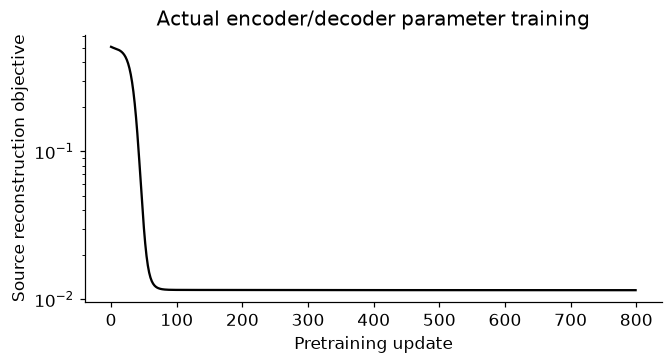

In [3]:
v=np.array([.8,.6]);orth=np.array([-.6,.8]);latent=rng.normal(size=1200)
source=latent[:,None]*v+rng.normal(0,.15,(1200,1))*orth;source_mean=source.mean(0);Xs=source-source_mean
e=rng.normal(0,.15,2);d=rng.normal(0,.15,2)
def ae_value_grad(X,e,d):
 z=X@e;error=z[:,None]*d-X
 return .5*np.mean(np.sum(error**2,axis=1)),X.T@(error@d)/len(X),error.T@z/len(X)
initial,ge,gd=ae_value_grad(Xs,e,d);h=1e-5
numerical=np.array([(ae_value_grad(Xs,e+h*unit,d)[0]-ae_value_grad(Xs,e-h*unit,d)[0])/(2*h) for unit in np.eye(2)])
assert np.allclose(ge,numerical,rtol=1e-7,atol=1e-9)
reconstruction_losses=[]
for _ in range(800):
 value,ge,gd=ae_value_grad(Xs,e,d);reconstruction_losses.append(value);e=e-.08*ge;d=d-.08*gd
last=ae_value_grad(Xs,e,d)[0]
assert last<initial*.1 and np.isfinite(e).all() and np.linalg.norm(e)>0
print('Source reconstruction objective:',initial,'->',last)
RESULTS['autoencoder_reconstruction_before_after']=[float(initial),float(last)]
fig,ax=plt.subplots(figsize=(6,3.2));ax.semilogy(reconstruction_losses,'k-');ax.set(xlabel='Pretraining update',ylabel='Source reconstruction objective',title='Actual encoder/decoder parameter training');plt.show()


<a id="frozen-encoder"></a>
## Reuse without fine-tuning the encoder

Generate a disjoint downstream sample with the same feature semantics. The first 60 labels fit a scalar affine head; the next 30 are development diagnostics and the last 30 form a fixed final assessment. The source encoder is frozen, source mean reused and no settings are selected with assessment labels. Fine-tuning would allow encoder parameters to change; this run does not. This is a reuse mechanism, not proof that pretraining improves every task versus all baselines.


In [4]:
latent_down=rng.normal(size=120);downstream=latent_down[:,None]*v+rng.normal(0,.15,(120,1))*orth
y_down=1.2*latent_down+.1+rng.normal(0,.1,120)
train=np.arange(60);development=np.arange(60,90);final=np.arange(90,120)
assert not set(train)&set(final) and not set(train)&set(development)
frozen_encoder=e.copy();codes=(downstream-source_mean)@e;design=np.column_stack([codes,np.ones(120)])
downstream_head=np.linalg.lstsq(design[train],y_down[train],rcond=None)[0]
final_predictions=design[final]@downstream_head;mae=np.mean(abs(final_predictions-y_down[final]))
assert np.array_equal(e,frozen_encoder) and final_predictions.shape==(30,)
print('Frozen encoder final synthetic MAE:',mae)
RESULTS['frozen_encoder_final_MAE']=float(mae);RESULTS['encoder_unchanged_during_head_fit']=bool(np.array_equal(e,frozen_encoder))


Frozen encoder final synthetic MAE: 0.06608973858050901


<a id="context-pretraining"></a>
## Train a tiny contextual predictor across tasks

This third, separate model predicts from support input/label pairs and a query. Gaussian kernel weights normalize to one; a single positive bandwidth h=exp(log_h) is learned across 200 synthetic affine tasks, each with five support points and six training queries. Support and query coordinates/labels are generated separately. The inputs are dimensionless, so log_h is dimensionless under a unit reference. This is an actually pretrained one-parameter contextual regressor, not a foundation model or a claim to implement general in-context learning.

For scores=-distance²/(2h²), dscore/dlog_h=distance²/h². Differentiating the normalized weighted mean gives sum(weights*(support_y-prediction)*dscore). Bounds [-3,1] and rate .15 are fixed numerical controls. Query labels enter pretraining loss, never the forward context.

**Predict:** can new support labels change the prediction while log_h stays fixed? Does changing a computed support weight count as updating a stored learned parameter?


In [5]:
E,m,q=200,5,6
support_x=rng.uniform(-1,1,(E,m));query_x=rng.uniform(-1,1,(E,q))
a_task=rng.normal(0,1,E);b_task=rng.normal(0,.5,E)
support_y=a_task[:,None]*support_x+b_task[:,None]+rng.normal(0,.1,(E,m))
query_y=a_task[:,None]*query_x+b_task[:,None]+rng.normal(0,.1,(E,q))
def contextual_predict_grad(log_h,sx,sy,qx):
 dist2=(qx[:,:,None]-sx[:,None,:])**2;h2=np.exp(2*log_h)
 scores=-dist2/(2*h2);weights=special.softmax(scores,axis=-1)
 prediction=np.sum(weights*sy[:,None,:],axis=-1)
 derivative=np.sum(weights*(sy[:,None,:]-prediction[:,:,None])*dist2/h2,axis=-1)
 return prediction,derivative
log_h=-.2;pred,derivative=contextual_predict_grad(log_h,support_x,support_y,query_x)
initial_context=.5*np.mean((pred-query_y)**2)
grad=np.mean((pred-query_y)*derivative);h_fd=1e-5
vp=.5*np.mean((contextual_predict_grad(log_h+h_fd,support_x,support_y,query_x)[0]-query_y)**2)
vm=.5*np.mean((contextual_predict_grad(log_h-h_fd,support_x,support_y,query_x)[0]-query_y)**2)
assert np.isclose(grad,(vp-vm)/(2*h_fd),rtol=1e-6)
for _ in range(500):
 pred,derivative=contextual_predict_grad(log_h,support_x,support_y,query_x)
 log_h=float(np.clip(log_h-.15*np.mean((pred-query_y)*derivative),-3,1))
final_context=.5*np.mean((contextual_predict_grad(log_h,support_x,support_y,query_x)[0]-query_y)**2)
assert final_context<initial_context and log_h!=-.2
print('Context pretraining objective:',initial_context,'->',final_context,'learned h:',np.exp(log_h))
RESULTS['context_pretraining_before_after']=[float(initial_context),float(final_context)];RESULTS['learned_context_bandwidth']=float(np.exp(log_h))


Context pretraining objective: 0.10689017993589876 -> 0.04314067703760775 learned h: 0.21866452387187876


<a id="frozen-context"></a>
## New labeled context, frozen parameter

On a new task, supply four labeled support rows and predict queries without their labels. Shift every support label by +1 and call the same rule again. The prediction must shift by +1 because weights sum to one; no optimizer step occurs. This proves context dependence at fixed parameters, not generalization over arbitrary function families. The kernel averages support values and has limited extrapolation.


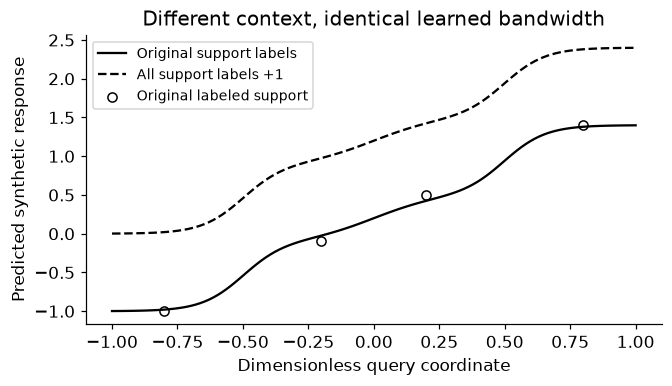

In [6]:
new_sx=np.array([[-.8,-.2,.2,.8]]);new_sy=1.5*new_sx+.2
new_q=np.linspace(-1,1,120)[None,:];saved_log_h=log_h
prediction,_=contextual_predict_grad(log_h,new_sx,new_sy,new_q)
shifted,_=contextual_predict_grad(log_h,new_sx,new_sy+1,new_q)
assert log_h==saved_log_h and np.allclose(shifted-prediction,1)
assert not np.isin(new_q.ravel(),new_sx.ravel()).any()
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(new_q[0],prediction[0],'k-',label='Original support labels');ax.plot(new_q[0],shifted[0],'k--',label='All support labels +1')
ax.scatter(new_sx[0],new_sy[0],facecolors='white',edgecolors='black',label='Original labeled support')
ax.set(xlabel='Dimensionless query coordinate',ylabel='Predicted synthetic response',title='Different context, identical learned bandwidth');ax.legend(fontsize=9);plt.show()
RESULTS['context_label_shift_max_error']=float(np.max(abs(shifted-prediction-1)))


<a id="exercises"></a>
## Exercises and optional hints

1. Change query-batch companions under the frozen scaler/model; then deliberately refit statistics to show the changed contract.
2. Add the feature schema, unit conventions and output link to the saved state. List extra optimizer/RNG state needed for exact training continuation.
3. Verify the decoder gradient too. Inject a low-variance task cue and investigate what a one-coordinate pretrained encoder discards.
4. Fine-tune encoder parameters using only downstream training labels, with a predeclared development selection and fresh final data. Distinguish that from the frozen-head experiment.
5. Give the contextual predictor a new support set without changing h. Then separately train h on new tasks and identify which operation changed parameters.
6. Test support extrapolation and a genuinely new task family. Agreement or low pretraining loss alone is not transfer validation.

**Hints:** fitted preprocessing is learned state, but pretraining here is real reconstruction/episodic model training for reuse. Context weighting is evaluated inside a forward function. Keeping parameters fixed is not the same as ignoring labeled context.

**Troubleshooting:** match channel order and source transformations; use stable softmax; never put query targets into their own support context. Official [StandardScaler](https://scikit-learn.org/1.9/modules/generated/sklearn.preprocessing.StandardScaler.html) and [leakage guidance](https://scikit-learn.org/1.9/common_pitfalls.html) document preprocessing roles. The two tiny pretraining algorithms are specified explicitly, without a hidden model download.


In [7]:
summary={'example_id':'code_020','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['training-only fitted preprocessing', 'frozen prediction state round trip', 'actual autoencoder reconstruction pretraining', 'frozen encoder downstream head', 'episodically pretrained contextual kernel', 'context changes output without parameter updates'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["training-only fitted preprocessing", "frozen prediction state round trip", "actual autoencoder reconstruction pretraining", "frozen encoder downstream head", "episodically pretrained contextual kernel", "context changes output without parameter updates"], "elapsed_seconds": 0.327, "example_id": "code_020", "hardware": "Darwin arm64 CPU", "results": {"autoencoder_reconstruction_before_after": [0.5092504638423034, 0.011497127442549866], "context_label_shift_max_error": 6.661338147750939e-16, "context_pretraining_before_after": [0.10689017993589876, 0.04314067703760775], "encoder_unchanged_during_head_fit": true, "frozen_encoder_final_MAE": 0.06608973858050901, "learned_context_bandwidth": 0.21866452387187876, "state_roundtrip_prediction_mm": 1.0781561694343151}, "seed": 420, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
